# testing fourier transforms
there are a few different scenarios we want to cover

$$ X(f) = F\{x(t)\} $$
$$ X(\omega) = F\{(x(t)\} $$
and of course the inverse versions of this

In [1]:
import em1d.transforms as tr
import torch
import matplotlib.pyplot as plt
import numpy as np

twopi_sqrt = np.sqrt(2*np.pi)

offset range:  -21 41


C:\Users\au646858\AppData\Local\Temp\ipykernel_29384\918115028.py:31: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  rout = torch.tensor(10**(i_offsets/self.smp_per_decade), dtype=torch.complex128)


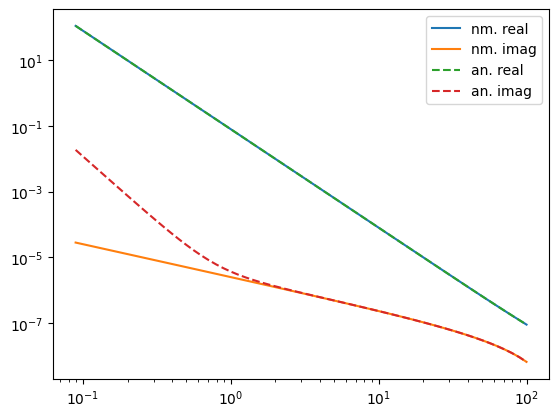

In [8]:
# from em1d.transforms import BaseHankel
from em1d.physics import freespace_u0, calc_wavenumber
from em1d.physics import halfspace_vmd

omega = torch.tensor([1e4])
def testhank(lamda):
    k = calc_wavenumber(0.01, omega, sqrt=False)
    u = torch.sqrt(lamda**2 - k)
    return lamda**3 / (lamda+u)
   
hkl = BaseHankel(testhank, 0, smp_per_decade=20)
r,Hk = hkl.range(1e-1, 1e2)
Hk /= 2*torch.pi

analytic = halfspace_vmd(0.01, omega, r)

plt.figure()
plt.loglog(r, -Hk.real, label='nm. real')
plt.loglog(r, -Hk.imag, label='nm. imag')
plt.loglog(r, -analytic.real, '--', label='an. real')
plt.loglog(r, -analytic.imag, '--', label='an. imag')
plt.legend()

offset range:  -31 31


C:\Users\au646858\AppData\Local\Temp\ipykernel_29384\918115028.py:31: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  rout = torch.tensor(10**(i_offsets/self.smp_per_decade), dtype=torch.complex128)


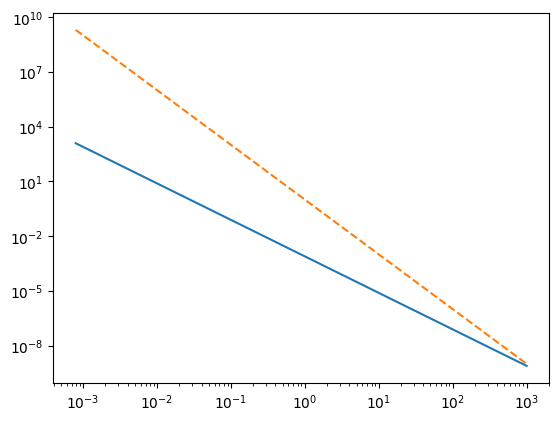

In [16]:
def testhank(lamda):
    return lamda

hkl = BaseHankel(testhank, 0)

rho,Hk = hkl.range(1e-3, 1e3)

analytic = rho**(-3)

plt.figure()
plt.loglog(rho, Hk)
plt.loglog(rho, analytic, '--')

In [23]:
class Fourier:
    def __init__(self, func, log10min=-20, log10max=10, smp_per_decade=16, device=None):
        self.func = func
        self.smp_per_decade = smp_per_decade
        self.n_decades = log10max-log10min
        self.lamda = 10**(np.arange(log10min*smp_per_decade,
                          log10max*smp_per_decade+1)*self.delta)
        self.v = np.log(self.lamda)
        self.lamda = torch.tensor(self.lamda, dtype=torch.complex128)

        self.fc = tr.optimized_coefficients_christensen1990(self.v, omega_0=np.pi/4, nu=-0.5, smp_per_decade=self.smp_per_decade)-1j*tr.optimized_coefficients_christensen1990(self.v, omega_0=np.pi/4, nu=0.5, smp_per_decade=self.smp_per_decade)
        self.fc  = torch.tensor(self.fc, dtype=torch.complex128)

        if device is not None:
            self.fc=self.fc.to(device)
            self.lamda=self.lamda.to(device)
        self.device = device 
        self.F = self.f1(self.lamda)*self.lamda

    def f1(self, lamda):
        return self.func(lamda/twopi_sqrt)/torch.sqrt(lamda)

    @property
    def delta(self):
        return 1./self.smp_per_decade
        
    def range(self, fmin, fmax):

        fmin /= twopi_sqrt
        fmax /= twopi_sqrt

        imin = int(np.floor(self.smp_per_decade*np.log10(fmin))-1)
        imax = int(np.ceil(self.smp_per_decade*np.log10(fmax))+2)
        print('index ranges: ', imin, imax)
        i_offsets = torch.tensor(np.arange(imin, imax))
        fout = 10**(i_offsets/self.smp_per_decade)
        Ht = torch.zeros(self.F.shape[:-1]+fout.shape, dtype=torch.complex128)
        
        if self.device is not None:
            fout=fout.to(self.device)
            Ht=Ht.to(self.device)
            i_offsets=i_offsets.to(self.device)

        for i,i_offset in enumerate(i_offsets):
            if i_offset==0:
                Ht[..., i] = torch.einsum('...i,...i->...', self.F, self.fc)
            elif i_offset>0:
                Ht[..., i] = torch.einsum('...i,...i->...', self.F[..., :-i_offset], self.fc[..., i_offset:])
            else:
                i_offset *= -1
                Ht[..., i] = torch.einsum('...i,...i->...', self.fc[..., :-i_offset], self.F[..., i_offset:])
        return fout/twopi_sqrt, Ht/torch.sqrt(fout)
    
    def __repr__(self) -> str:
        return 'x(t)->X(f)'

class invFourier(Fourier):
    def __init__(self, func, log10min=-20, log10max=20, smp_per_decade=20, device=None):
        super().__init__(func, log10min, log10max, smp_per_decade, device)
        self.fc = self.fc.real - 1j*self.fc.imag
    
    def __repr__(self) -> str:
        return 'X(f)->x(t)'

In [24]:
a = 1e-1
def f1(x):
    return torch.exp(-a*x**2)

def F1(k):
    return np.sqrt(torch.pi/a)*torch.exp(-torch.pi*torch.pi*k*k/a)

x(t)->X(f)
index ranges:  -104 28
tensor([1.2616e-07, 1.4568e-07, 1.6823e-07, 1.9427e-07, 2.2434e-07, 2.5907e-07,
        2.9916e-07, 3.4547e-07, 3.9894e-07, 4.6069e-07, 5.3200e-07, 6.1434e-07,
        7.0943e-07, 8.1924e-07, 9.4604e-07, 1.0925e-06, 1.2616e-06, 1.4568e-06,
        1.6823e-06, 1.9427e-06, 2.2434e-06, 2.5907e-06, 2.9916e-06, 3.4547e-06,
        3.9894e-06, 4.6069e-06, 5.3200e-06, 6.1434e-06, 7.0943e-06, 8.1924e-06,
        9.4604e-06, 1.0925e-05, 1.2616e-05, 1.4568e-05, 1.6823e-05, 1.9427e-05,
        2.2434e-05, 2.5907e-05, 2.9916e-05, 3.4547e-05, 3.9894e-05, 4.6069e-05,
        5.3200e-05, 6.1434e-05, 7.0943e-05, 8.1924e-05, 9.4604e-05, 1.0925e-04,
        1.2616e-04, 1.4568e-04, 1.6823e-04, 1.9427e-04, 2.2434e-04, 2.5907e-04,
        2.9916e-04, 3.4547e-04, 3.9894e-04, 4.6069e-04, 5.3200e-04, 6.1434e-04,
        7.0943e-04, 8.1924e-04, 9.4604e-04, 1.0925e-03, 1.2616e-03, 1.4568e-03,
        1.6823e-03, 1.9427e-03, 2.2434e-03, 2.5907e-03, 2.9916e-03, 3.4547e-03,
      

(0.1, 10.0)

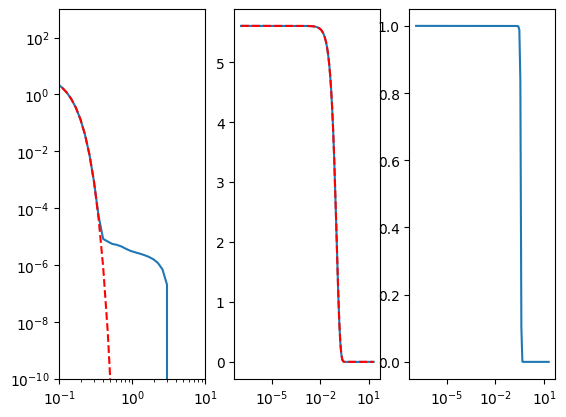

In [27]:
ft = Fourier(f1)
print(ft)
f,F = ft.range(1e-6,1e2)
print(f)

h1 = F1(f)

h1 = h1.numpy()
F = F.numpy()
f = f.numpy()

fig,axs = plt.subplots(1,3)
axs[0].loglog(f, F)
axs[0].loglog(f, h1, 'r--')
axs[0].set_ylim(1e-10, 1e3)
axs[1].semilogx(f, F)
axs[1].semilogx(f, h1, 'r--')
axs[2].semilogx(f, h1/F.real)
print(np.allclose(F.real, h1.real))
axs[0].set_xlim(1e-1, 1e1)

X(f)->x(t)
index ranges:  -129 55
False


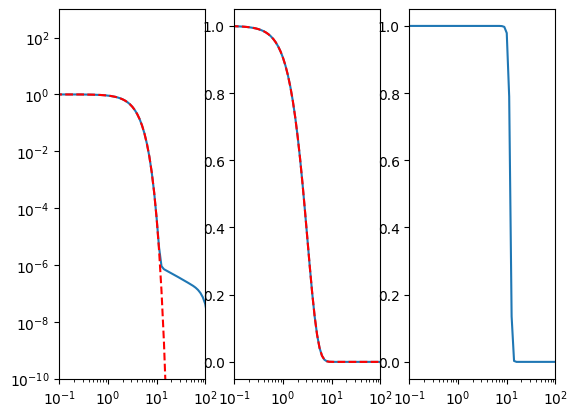

In [28]:
ift = invFourier(F1)
print(ift)
t,ft = ift.range(1e-6,1e3)

h1 = f1(t)

h1 = h1.numpy()
ft = ft.numpy()
t = t.numpy()

fig,axs = plt.subplots(1,3, sharex=True)
axs[0].loglog(t, ft)
axs[0].loglog(t, h1, 'r--')
axs[0].set_ylim(1e-10, 1e3)
axs[0].set_xlim(1e-1, 1e2)
axs[1].semilogx(t, ft)
axs[1].semilogx(t, h1, 'r--')
axs[2].semilogx(t, h1/ft.real)
print(np.allclose(ft.real, h1.real))